## GeoRAG-ML: An Explainable Geospatial Intelligence Framework Integrating Earth Observation, Machine Learning, and Retrieval-Augmented Generation for Environmental Change Analysis and Risk Prediction

**Author:** Md Khadem Ali · [khademali.com](https://khademali.com)

---
## 01 · Research Overview

This notebook implements a reproducible geospatial machine-learning workflow with three coupled components:

1. **Earth observation analytics**, cloud-masked Sentinel-2 spectral indices (NDVI, NDWI, MNDWI, NDBI), multi-temporal change screening, and terrain/rainfall context.
2. **Explainable risk prediction**, four classifiers (Logistic Regression, SVM, Random Forest, XGBoost) evaluated with **buffered spatial cross-validation** and a **held-out geographic region**, interpreted with **SHAP**.
3. **Retrieval-Augmented Generation (RAG)**, a FAISS-based retrieval system over methodological documentation that answers only from retrieved evidence and refuses when evidence is insufficient.

**Target.** *Urban heat risk*: a pixel is **high risk** when its Landsat land-surface temperature (LST) in the later period is at or above the study-area 75th percentile. Predictors come from *other* sensors/products (Sentinel-2, SRTM, CHIRPS), which limits direct target leakage.

> **Data-mode transparency.** The notebook has two data modes. **Real mode** reads GeoTIFFs exported from Google Earth Engine (`src/gee_acquisition.py`). **Synthetic mode** simulates a scene so that every step can be executed and verified without network access. The banner below states which mode produced the outputs in this copy of the notebook. Synthetic outputs verify the *code*; they are **not** findings about the real world.

In [1]:
import os, sys, json, logging, platform, warnings
from pathlib import Path

# Work from the repository root regardless of where Jupyter was launched
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT); sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, yaml, matplotlib, matplotlib.pyplot as plt, seaborn as sns
import sklearn, xgboost, shap, faiss
from IPython.display import display, Markdown

from src import remote_sensing as rs, preprocessing as pp, modeling as md, explainability as xai
from src import rag_pipeline as rp, visualization as viz

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.basicConfig(level=logging.WARNING)

cfg = yaml.safe_load(open("config/config.yaml"))
SEED = cfg["random_seed"]
np.random.seed(SEED)                      # global seed; every stochastic step below also receives SEED explicitly
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:.4f}".format)

versions = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "xgboost": xgboost.__version__, "shap": shap.__version__,
            "faiss": faiss.__version__, "matplotlib": matplotlib.__version__}
print("Environment:", versions); print("Random seed:", SEED)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment: {'python': '3.12.3', 'numpy': '2.4.4', 'pandas': '3.0.2', 'scikit-learn': '1.8.0', 'xgboost': '3.4.1', 'shap': '0.54.1', 'faiss': '1.15.1', 'matplotlib': '3.10.8'}
Random seed: 42


## 02 · Abstract and Research Questions

**Abstract (design statement).** Environmental risk models are frequently reported with random train/test splits that overstate accuracy on spatially autocorrelated data, and their outputs are rarely connected to the methodological documentation needed to audit them. GeoRAG-ML couples (i) multi-temporal Earth-observation indicators, (ii) a leakage-aware, spatially validated model comparison with SHAP explanations, and (iii) a retrieval system that returns source-attributed evidence for methodological and model-performance questions and declines to answer when evidence is lacking. Quantitative results are computed by the cells below and summarised in Section 16; no numbers are written into the text in advance.

**Research questions**

| # | Question | Where answered |
|---|----------|----------------|
| RQ1 | How do spectral indices differ between the two pre-monsoon periods, and which differences can be called *candidate* change? | §07–08 |
| RQ2 | Can optical, terrain and rainfall predictors classify high-LST pixels in a **geographically held-out** region, and which of four algorithms performs best? | §10–11 |
| RQ3 | How much does random cross-validation overstate performance relative to buffered spatial cross-validation? | §10 |
| RQ4 | Which predictors does the best tree model rely on, and in which direction (SHAP)? | §12 |
| RQ5 | Can a retrieval pipeline return source-attributed evidence for methodology questions and refuse unsupported ones? | §14–15 |

## 03 · Study Area and Data Sources

**Study area.** Natore District, Bangladesh (Rajshahi Division), a Ganges–Brahmaputra floodplain landscape with a river corridor, dense rural settlement, irrigated cropland and small urban centres. Coordinates are handled in **WGS 84 / UTM 45N (EPSG:32645)**.

**Periods.** Two pre-monsoon composites (1 Mar – 30 Apr) for 2019 (*t₁*) and 2025 (*t₂*). Using the same calendar window limits phenological differences.

| Layer | Source (Earth Engine ID) | Native resolution | Role |
|---|---|---|---|
| Surface reflectance B3, B4, B8, B11 | Sentinel-2 L2A `COPERNICUS/S2_SR_HARMONIZED` | 10–20 m | Spectral indices (predictors) |
| Land surface temperature | Landsat 8/9 C2 L2 `LANDSAT/LC08/C02/T1_L2`, `LANDSAT/LC09/C02/T1_L2` (ST_B10) | 100 m (resampled to 30 m) | **Target definition only** |
| Elevation, slope | SRTM `USGS/SRTMGL1_003` | ~30 m | Predictors |
| Precipitation | CHIRPS `UCSB-CHG/CHIRPS/DAILY` | ~5.5 km | Predictor (regional context) |
| Land cover | ESA WorldCover `ESA/WorldCover/v200` | 10 m | Reference layer (not a predictor) |
| Documentation | `documents/*.txt` (authored for this project) | – | RAG corpus |

In [2]:
sa = cfg["study_area"]
display(pd.Series({"Study area": sa["name"], "Fallback bbox (lon/lat)": sa["bbox_lonlat"], "CRS": f"EPSG:{sa['utm_epsg']}",
                   "t1 window": f"{cfg['periods']['t1']['start']} → {cfg['periods']['t1']['end']}",
                   "t2 window": f"{cfg['periods']['t2']['start']} → {cfg['periods']['t2']['end']}",
                   "Target": f"LST(t2) ≥ scene P{cfg['target']['lst_percentile']}"}, name="configuration").to_frame())
L1, L2 = cfg["periods"]["t1"]["label"], cfg["periods"]["t2"]["label"]

,configuration
Study area,"Natore District, Bangladesh"
Fallback bbox (lon/lat),"[88.65, 24.05, 89.35, 24.65]"
CRS,EPSG:32645
t1 window,2019-03-01 → 2019-04-30
t2 window,2025-03-01 → 2025-04-30
Target,LST(t2) ≥ scene P75


## 04 · Data Acquisition

**Real data.** Run the Earth Engine export once (credentials stay on your machine; nothing is stored in the repository):

```bash
earthengine authenticate
python -m src.gee_acquisition --project YOUR_CLOUD_PROJECT     # export tasks → Google Drive folder "GeoRAG-ML"
python -m src.gee_acquisition --dry-run                        # print the plan without contacting Earth Engine
```

Download the eight GeoTIFFs into `data/raw/` (names are listed in the module docstring). The loader checks that all rasters are co-registered. If they are missing, `data_mode: auto` in `config/config.yaml` selects the synthetic demonstration scene.

**Synthetic scene (verification only).** `rs.simulate_scene` builds a river, ponds, expanding urban nuclei, cropland patches with harvest-phase variation, cloud/shadow contamination, coarse CHIRPS-like rainfall blocks, and an LST field with a spatially structured component that predictors cannot see. Because LST is generated from simulated land cover, **a model can recover those relationships by construction**; the exercise tests the pipeline, not nature.

In [3]:
mode = cfg["data_mode"]
if mode == "auto":
    mode = "real" if rs.real_data_available("data/raw") else "synthetic"

if mode == "real":
    scene = rs.load_scene_from_geotiffs("data/raw")
else:
    scene = rs.simulate_scene(sa["bbox_lonlat"], sa["utm_epsg"], cfg["grid"]["synthetic_pixel_m"], SEED)

meta, IS_SYNTH = scene["meta"], scene["meta"]["synthetic"]
viz.set_style("figures", synthetic=IS_SYNTH)
banner = ("⚠️ **SYNTHETIC DEMONSTRATION MODE** — every number and map in this copy of the notebook describes a simulated scene. "
          "They verify that the pipeline runs; they are not findings about Natore." if IS_SYNTH else
          "✅ **REAL-DATA MODE** — outputs derive from the GeoTIFFs in `data/raw/`.")
display(Markdown(banner))

h, w = meta["shape"]
inv = pd.DataFrame({"layer": ["s2_t1 (B3,B4,B8,B11)", "s2_t2", "lst_t1", "lst_t2", "elevation", "slope", "precip_t1", "precip_t2", "landcover"],
                    "missing_%": [100 * np.isnan(scene["s2_t1"]["B8"]).mean(), 100 * np.isnan(scene["s2_t2"]["B8"]).mean(),
                                  100 * np.isnan(scene["lst_t1"]).mean(), 100 * np.isnan(scene["lst_t2"]).mean(),
                                  100 * np.isnan(scene["elevation"]).mean(), 100 * np.isnan(scene["slope"]).mean(),
                                  100 * np.isnan(scene["precip_t1"]).mean(), 100 * np.isnan(scene["precip_t2"]).mean(), 0.0]})
print(f"Mode: {mode} | grid: {h} x {w} px | pixel: {meta['pixel_m']:.0f} m | CRS: {meta['crs']} | extent ≈ {w*meta['pixel_m']/1000:.0f} x {h*meta['pixel_m']/1000:.0f} km")
display(inv.set_index("layer"))

⚠️ **SYNTHETIC DEMONSTRATION MODE** — every number and map in this copy of the notebook describes a simulated scene. They verify that the pipeline runs; they are not findings about Natore.

Mode: synthetic | grid: 225 x 234 px | pixel: 300 m | CRS: EPSG:32645 | extent ≈ 70 x 68 km


,missing_%
layer,
"s2_t1 (B3,B4,B8,B11)",7.1301
s2_t2,8.5641
lst_t1,0.0000
lst_t2,0.0000
elevation,0.0000
slope,0.0000
precip_t1,0.0000
precip_t2,0.0000
landcover,0.0000


## 05 · Data Preprocessing

**Cloud and shadow masking.** Sentinel-2 pixels with Scene Classification Layer values 3 (shadow), 8/9 (cloud), 10 (cirrus) and 11 (snow) are set to missing; Landsat uses `QA_PIXEL` bits 1–5. Reflectance is scaled as $\rho = \text{DN}\times 10^{-4}$ (Sentinel-2) or $\rho = \text{DN}\times 2.75\times10^{-5} - 0.2$ (Landsat), and Landsat surface temperature as $T_K = \text{DN}\times 0.00341802 + 149.0$, $T_{^\circ C}=T_K-273.15$. In real mode this is done server-side in Earth Engine; the same rules are implemented for local arrays in `src/remote_sensing.py`.

**Missing data policy.** Masked pixels stay `NaN` in rasters. For modelling, a pixel is kept if its target exists and at least 80 % of its predictors are valid; remaining gaps are median-imputed **inside the model pipeline, so statistics come from training folds only**.

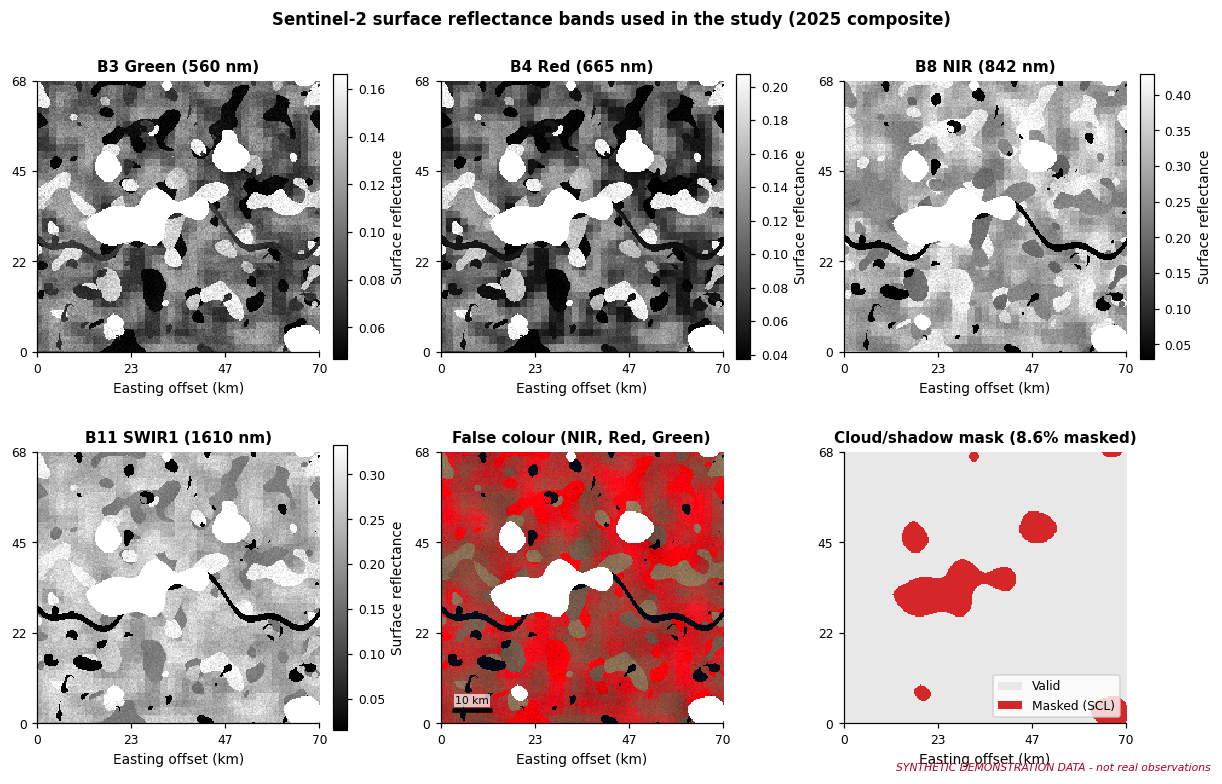

**Interpretation.** Cloud/shadow masking removed 7.1% of pixels in the 2019 composite and 8.6% in the 2025 composite. Pixels masked in *either* date cannot support change analysis, so change statistics in §08 are computed on pixels valid in both dates.

In [4]:
fig = viz.fig_band_visualization(scene, "t2", L2); plt.show()
masked = {t: 100 * np.isnan(scene[f"s2_{t}"]["B8"]).mean() for t in ("t1", "t2")}
display(Markdown(f"**Interpretation.** Cloud/shadow masking removed {masked['t1']:.1f}% of pixels in the {L1} composite and "
                 f"{masked['t2']:.1f}% in the {L2} composite. Pixels masked in *either* date cannot support change analysis, so change statistics in §08 "
                 "are computed on pixels valid in both dates."))

## 06 · Exploratory Data Analysis

We inspect the target field (LST), its spread, and the reference land-cover composition before modelling. The binary target is defined relative to the scene:

$$ y_i = \mathbb{1}\left[\,\text{LST}_{t_2}(i) \ge Q_{0.75}\big(\text{LST}_{t_2}\big)\right] $$

so roughly 25 % of valid pixels are positive by construction. The class is *relative*, not an absolute heat-stress threshold.

,LST 2019 (°C),LST 2025 (°C)
count,52650.0000,52650.0000
mean,33.9211,35.6129
std,2.5743,2.6151
min,23.6069,23.7678
25%,32.5227,34.1716
50%,33.9924,35.6426
75%,35.5123,37.2079
max,44.2622,46.2104


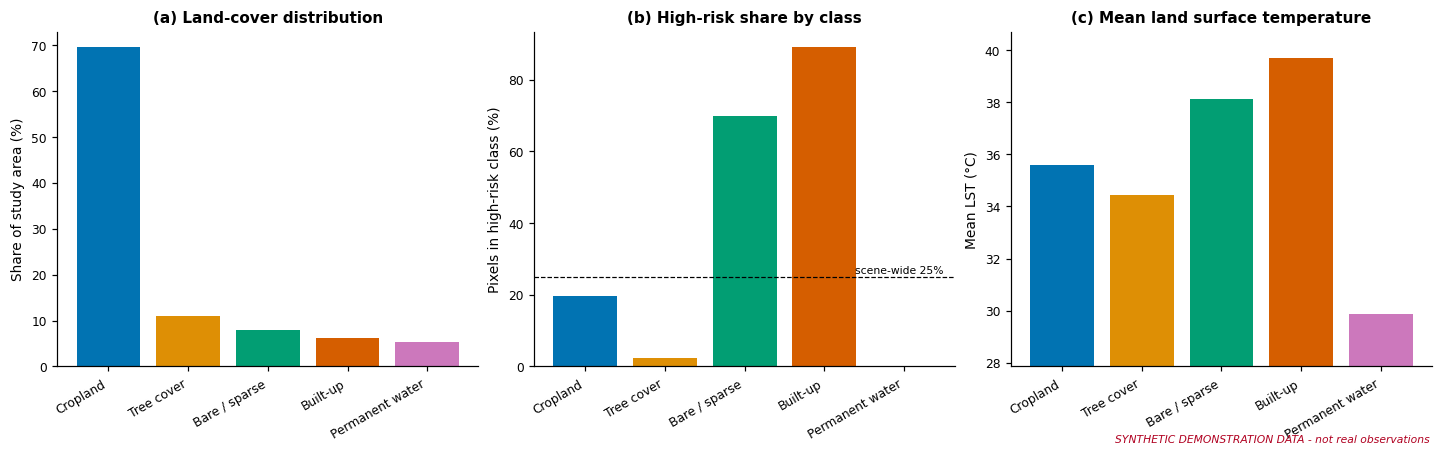

,area_km2,pct,high_risk_pct,mean_lst
class,,,,
Cropland,3293.1900,69.5000,19.6400,35.5900
Tree cover,518.9400,10.9500,2.3900,34.4300
Bare / sparse,375.8400,7.9300,69.8000,38.1200
Built-up,295.5600,6.2400,89.0100,39.7100
Permanent water,254.9700,5.3800,0.0000,29.8600


**Interpretation.** The high-risk threshold is LST ≥ 37.21 °C. The reference land-cover class with the highest share of high-risk pixels is **Built-up** (89.0% vs 25% expected under independence). In this synthetic scene that pattern follows directly from how the simulator assigns class temperatures.

In [5]:
lst2 = scene["lst_t2"]; y_ras, lst_thr = pp.high_risk_labels(lst2, cfg["target"]["lst_percentile"])
desc = pd.DataFrame({f"LST {L1} (°C)": pd.Series(scene["lst_t1"][np.isfinite(scene["lst_t1"])]).describe(),
                     f"LST {L2} (°C)": pd.Series(lst2[np.isfinite(lst2)]).describe()})
display(desc)
fig6, lc_table = viz.fig_landcover_distribution(scene["landcover"], lst2, lst_thr, meta); plt.show()
display(lc_table.round(2).set_index("class"))
top = lc_table.sort_values("high_risk_pct", ascending=False).iloc[0]
display(Markdown(f"**Interpretation.** The high-risk threshold is LST ≥ {lst_thr:.2f} °C. The reference land-cover class with the highest "
                 f"share of high-risk pixels is **{top['class']}** ({top['high_risk_pct']:.1f}% vs 25% expected under independence). "
                 + ("In this synthetic scene that pattern follows directly from how the simulator assigns class temperatures." if IS_SYNTH else
                    "Class-level differences are descriptive; they do not isolate causal land-cover effects.")))

## 07 · Remote Sensing Indices

$$\text{NDVI}=\frac{\rho_{NIR}-\rho_{Red}}{\rho_{NIR}+\rho_{Red}},\quad
\text{NDWI}=\frac{\rho_{Green}-\rho_{NIR}}{\rho_{Green}+\rho_{NIR}},\quad
\text{MNDWI}=\frac{\rho_{Green}-\rho_{SWIR1}}{\rho_{Green}+\rho_{SWIR1}},\quad
\text{NDBI}=\frac{\rho_{SWIR1}-\rho_{NIR}}{\rho_{SWIR1}+\rho_{NIR}}$$

(Rouse et al., 1974; McFeeters, 1996; Xu, 2006; Zha et al., 2003). Sentinel-2 bands: Green = B3, Red = B4, NIR = B8, SWIR1 = B11. The indices are computed from **cloud-masked** reflectance, and division by zero returns `NaN`.

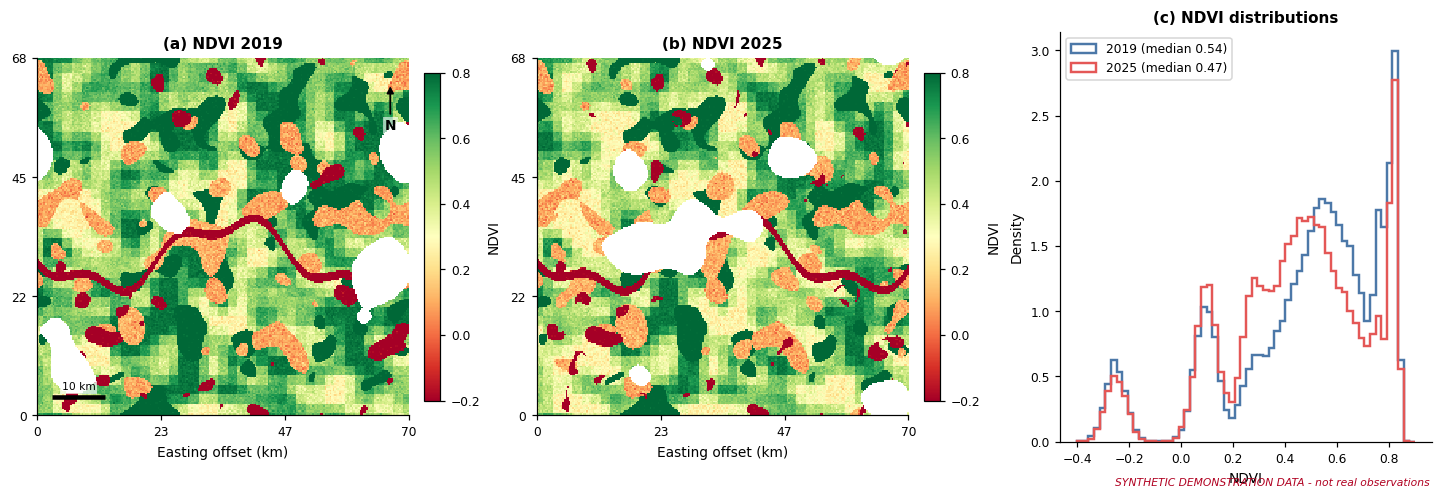

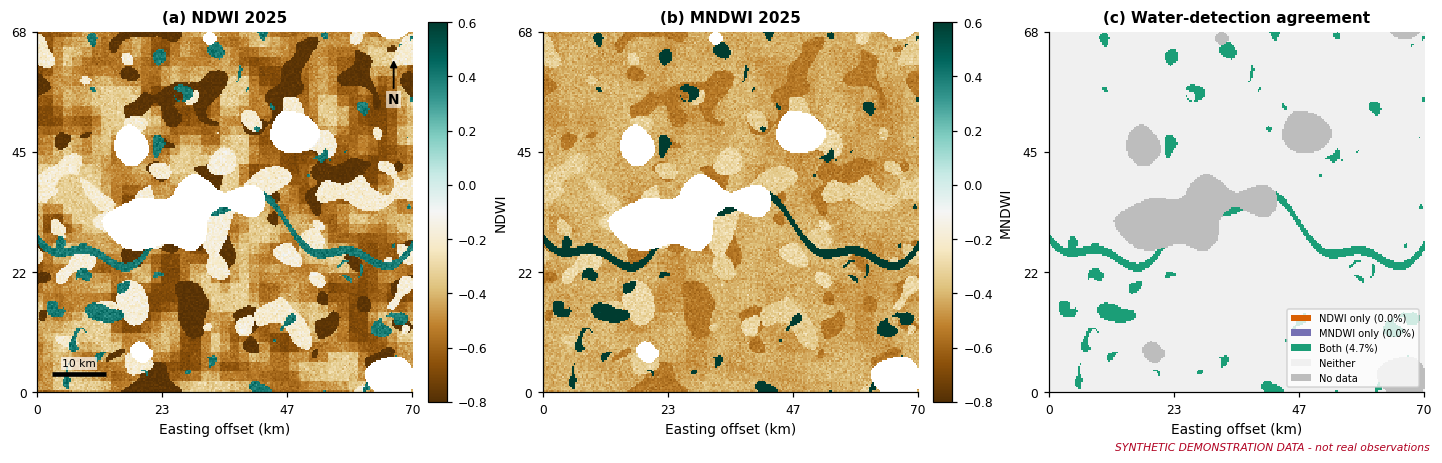

,NDVI,NDWI,MNDWI,NDBI,pixels
class,,,,,
Tree cover,0.8180,-0.7770,-0.5450,-0.4030,5766
Cropland,0.4870,-0.4970,-0.4290,-0.0950,36591
Built-up,0.1090,-0.1750,-0.2990,0.1310,3284
Bare / sparse,0.0920,-0.2000,-0.3320,0.1420,4176
Permanent water,-0.2500,0.4010,0.6470,-0.3320,2833


**Interpretation.** Median NDVI moved from 0.540 (2019) to 0.465 (2025). 0.0% of pixels are water by NDWI but not by MNDWI (NDWI-only detections are the usual sign of built-up or bare surfaces being mistaken for water; none are present here). MNDWI is used for the distance-to-water predictor. Index values are scene- and season-dependent; thresholds are not transferable.

In [6]:
I1, I2 = rs.compute_indices(scene["s2_t1"]), rs.compute_indices(scene["s2_t2"])
fig = viz.fig_ndvi(I1, I2, meta, L1, L2); plt.show()
fig = viz.fig_water_indices(I2, meta, L2); plt.show()

# Index statistics by reference land-cover class (t2)
rows = []
for code_, name in rs.LC_NAMES.items():
    m = (scene["landcover"] == code_)
    if m.sum() > 0:
        rows.append({"class": name, **{k.upper(): np.nanmean(v[m]) for k, v in I2.items()}, "pixels": int(m.sum())})
by_class = pd.DataFrame(rows).set_index("class"); display(by_class.round(3))

nd_only = np.mean((np.nan_to_num(I2["ndwi"], nan=-1) > 0) & (np.nan_to_num(I2["mndwi"], nan=-1) <= 0)) * 100
display(Markdown(f"**Interpretation.** Median NDVI moved from {np.nanmedian(I1['ndvi']):.3f} ({L1}) to {np.nanmedian(I2['ndvi']):.3f} ({L2}). "
                 f"{nd_only:.1f}% of pixels are water by NDWI but not by MNDWI"
                 + (" (NDWI-only detections are the usual sign of built-up or bare surfaces being mistaken for water; none are present here). " if nd_only < 0.5 else " — the pattern expected when NDWI responds to built-up or bare surfaces. ")
                 + "MNDWI is used for the distance-to-water predictor. Index values are scene- and season-dependent; thresholds are not transferable."))

## 08 · Spatiotemporal Analysis

Differences $\Delta I = I_{t_2} - I_{t_1}$ are screened with simple thresholds (from `config.yaml`) to produce **candidate change classes**.

> **Spectral-index change ≠ validated land-cover transition.** A fall in NDVI can be a crop harvested earlier, residual cloud or drier soil; a rise in NDBI can be bare field or post-harvest stubble. Declaring a land-cover *transition* requires independent reference samples and an accuracy assessment (e.g. Olofsson et al., 2014). The map below is therefore a screening product, and WorldCover here is a single-epoch layer that cannot validate change.

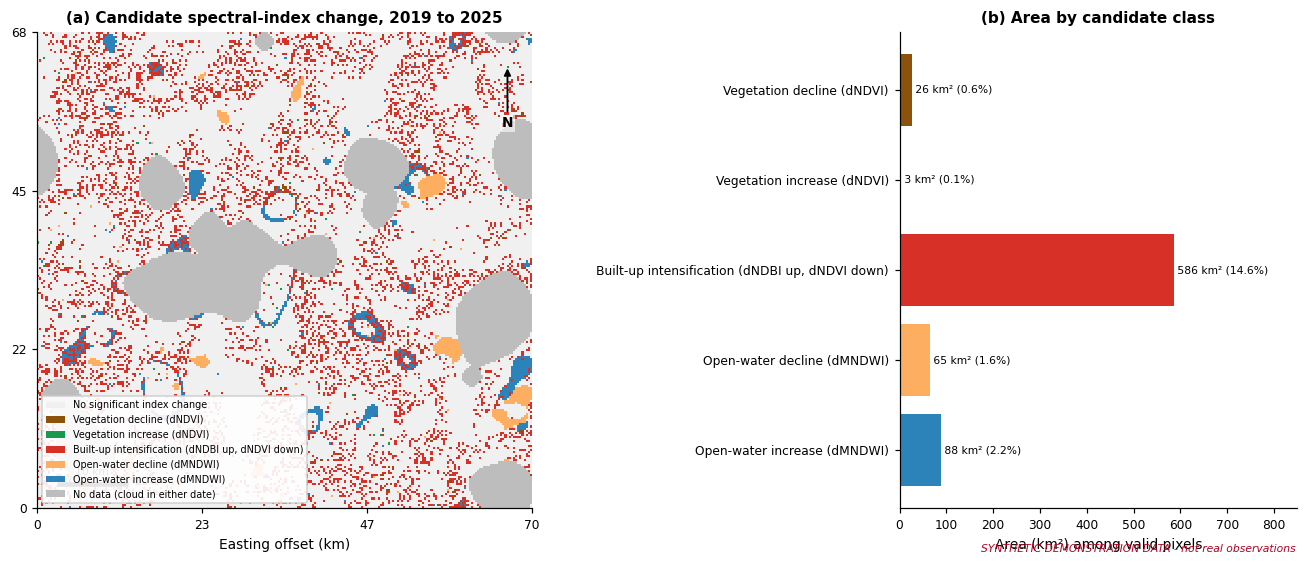

,area_km2,share_of_valid_%
candidate class,,
No significant index change,3247.2900,80.8700
Vegetation decline (dNDVI),25.7400,0.6400
Vegetation increase (dNDVI),2.9700,0.0700
"Built-up intensification (dNDBI up, dNDVI down)",585.9000,14.5900
Open-water decline (dMNDWI),65.2500,1.6300
Open-water increase (dMNDWI),88.1100,2.1900


**Interpretation.** 84.7% of pixels are valid in both dates. The mean LST difference (2025 − 2019) over valid pixels is +1.69 °C. Candidate built-up intensification covers 585.9 km² (14.6% of valid pixels), but because crop-harvest timing can raise NDBI and lower NDVI, this is an upper-bound screen, not an urban-growth estimate.

In [7]:
ch_cfg = cfg["change"]
change, dI = rs.classify_index_change(I1, I2, ch_cfg["ndvi_threshold"], ch_cfg["ndbi_threshold"], ch_cfg["mndwi_threshold"])
fig = viz.fig_change_map(change, meta, L1, L2); plt.show()

pix_km2 = (meta["pixel_m"] / 1000) ** 2
valid = change >= 0
chg = pd.DataFrame({"candidate class": list(rs.CHANGE_CLASSES.values()),
                    "area_km2": [(change == k).sum() * pix_km2 for k in rs.CHANGE_CLASSES],
                    "share_of_valid_%": [100 * (change == k).sum() / valid.sum() for k in rs.CHANGE_CLASSES]}).set_index("candidate class")
display(chg.round(2))

dlst = scene["lst_t2"] - scene["lst_t1"]
display(Markdown(f"**Interpretation.** {100*valid.mean():.1f}% of pixels are valid in both dates. The mean LST difference ({L2} − {L1}) over valid pixels is "
                 f"{np.nanmean(dlst):+.2f} °C. Candidate built-up intensification covers {chg.iloc[3,0]:.1f} km² ({chg.iloc[3,1]:.1f}% of valid pixels), "
                 "but because crop-harvest timing can raise NDBI and lower NDVI, this is an upper-bound screen, not an urban-growth estimate."))

## 09 · Feature Engineering

| Feature | Definition | Sensor / product |
|---|---|---|
| `ndvi`, `ndwi`, `mndwi`, `ndbi` | indices at $t_2$ | Sentinel-2 |
| `ndvi_focal5`, `ndbi_focal5` | 5×5 NaN-aware neighbourhood mean (spatial context) | Sentinel-2 |
| `d_ndvi`, `d_ndbi`, `d_mndwi` | $I_{t_2}-I_{t_1}$ | Sentinel-2 |
| `dist_water_m` | Euclidean distance to nearest pixel with MNDWI > 0 in either date | Sentinel-2 |
| `elevation`, `slope` | terrain | SRTM |
| `precip_t2` | accumulated precipitation over the $t_2$ window | CHIRPS |

**Leakage controls.** (1) The target comes from Landsat thermal data; no thermal feature is a predictor (`assert_no_leakage` checks names). (2) Coordinates are **not** features, so the model cannot memorise location. (3) Imputation/scaling live in the pipelines. (4) The label threshold is a scene-wide percentile (a labelling convention, not a fitted quantity).

Sampled **9,000** of 44,614 valid pixels; positive-class rate **0.261**; LST threshold **37.21 °C**.

,ndvi,ndwi,mndwi,ndbi,ndvi_focal5,ndbi_focal5,d_ndvi,d_ndbi,d_mndwi,dist_water_m,elevation,slope,precip_t2
missing_rate,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


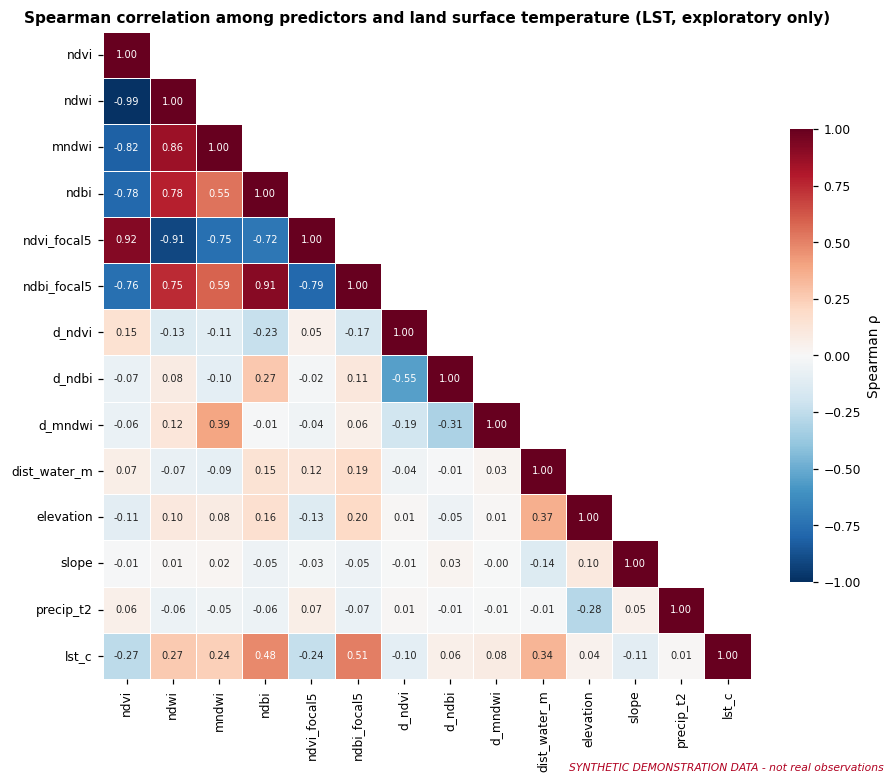

**Interpretation.** Most collinear predictor pairs: `ndwi`–`ndvi` (|ρ|=0.99); `ndvi_focal5`–`ndvi` (|ρ|=0.92); `ndbi_focal5`–`ndbi` (|ρ|=0.91); `ndvi_focal5`–`ndwi` (|ρ|=0.91). Strongest rank correlations with LST: `ndbi_focal5` (ρ=+0.51); `ndbi` (ρ=+0.48); `dist_water_m` (ρ=+0.34). Collinearity does not harm tree-model accuracy but spreads SHAP credit among related features (§12).

In [8]:
df, feat_rasters, info = pp.build_feature_table(scene, cfg, seed=SEED)
df.attrs["block_size_m"] = cfg["cv"]["block_size_m"]
X_all, y_all = df[pp.FEATURES], df["target"].to_numpy()
pp.assert_no_leakage(pp.FEATURES)

display(Markdown(f"Sampled **{info['n_sampled']:,}** of {info['n_valid_pixels']:,} valid pixels; positive-class rate **{info['positive_rate']:.3f}**; "
                 f"LST threshold **{info['lst_threshold_c']:.2f} °C**."))
miss = pd.Series(info["missing_rate_per_feature"], name="missing_rate"); display(miss.to_frame().T)

fig7, corr = viz.fig_correlation(df, pp.FEATURES); plt.show()
pairs = (corr.abs().where(np.tril(np.ones(corr.shape, dtype=bool), -1)).stack().sort_values(ascending=False))
pairs = pairs[[("lst_c" not in a and "lst_c" not in b) for a, b in pairs.index]].head(4)
lst_corr = corr["lst_c"].drop("lst_c").sort_values(key=np.abs, ascending=False).head(3)
display(Markdown("**Interpretation.** Most collinear predictor pairs: " + "; ".join(f"`{a}`–`{b}` (|ρ|={v:.2f})" for (a, b), v in pairs.items()) +
                 ". Strongest rank correlations with LST: " + "; ".join(f"`{k}` (ρ={v:+.2f})" for k, v in lst_corr.items()) +
                 ". Collinearity does not harm tree-model accuracy but spreads SHAP credit among related features (§12)."))

## 10 · Machine Learning Modelling

### Why random splitting is not enough
Neighbouring pixels share temperature, vegetation and moisture. With a random split, almost every test pixel has near-identical training neighbours, so the model can score well by *interpolating* rather than by learning transferable relationships — performance is optimistic (Roberts et al., 2017). We therefore:

1. aggregate pixels into **spatial blocks** (`cv.block_size_m`),
2. cluster blocks into contiguous regions and hold out **one region** as the final test area (never used for tuning),
3. tune hyper-parameters with **buffered spatial K-fold** on the training region (each fold = one contiguous region; training samples in adjacent blocks are dropped),
4. report the gap between random and spatial CV for the same model.

Models: Logistic Regression, SVM (RBF), Random Forest, XGBoost; median imputation (+ standardisation for LR/SVM) are inside pipelines. Hyper-parameters are chosen by grid search maximising ROC-AUC under spatial CV (small grids; see `src/modeling.py`).

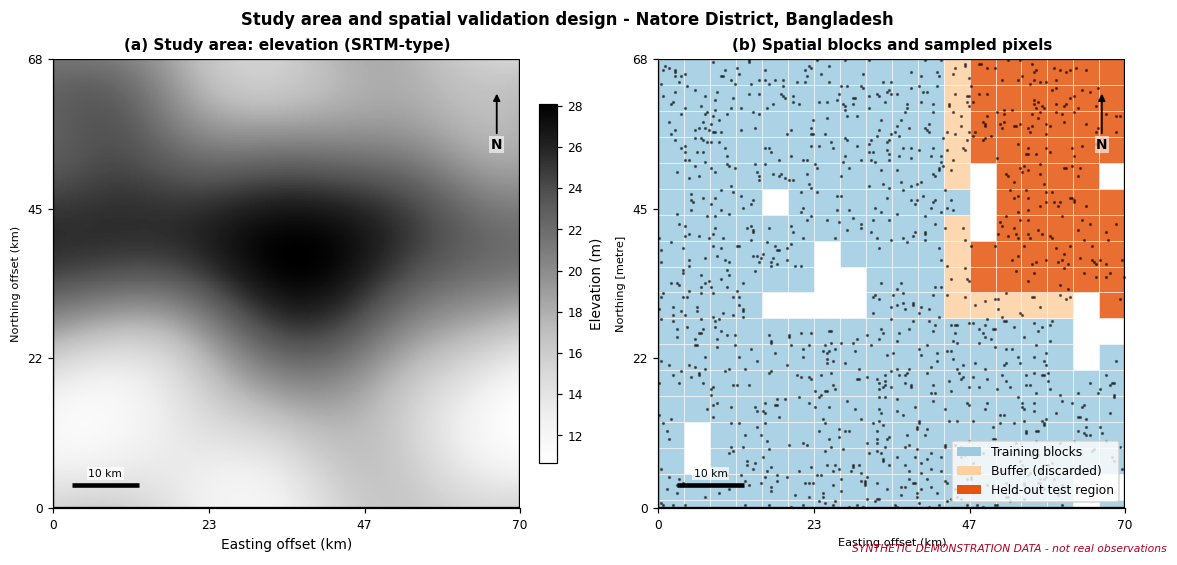

**Split audit.** train = 7,048, held-out test = 1,547, buffer-discarded = 405 samples; shared blocks between train and test = 0; index overlap = 0. Positive rate: train 0.274, test 0.240. Spatial CV folds (train/test sizes): 5,329/1,326, 5,396/1,296, 5,595/1,194, 5,047/1,663, 4,960/1,569.

In [9]:
tr_idx, te_idx, bu_idx = pp.split_blocks(df, cfg["cv"]["test_block_fraction"], cfg["cv"]["buffer_blocks"], SEED)
integrity = pp.check_split_integrity(df, tr_idx, te_idx)
assert integrity["index_overlap"] == 0 and integrity["shared_blocks"] == 0, "train/test leakage detected"

df_tr, df_te = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
X_tr, y_tr, X_te, y_te = df_tr[pp.FEATURES], df_tr["target"].to_numpy(), df_te[pp.FEATURES], df_te["target"].to_numpy()
cv_splits = pp.spatial_kfold_splits(df_tr, cfg["cv"]["n_splits"], cfg["cv"]["buffer_blocks"], SEED)

fig1 = viz.fig_study_area(scene, df, tr_idx, te_idx, bu_idx, sa["name"]); plt.show()
display(Markdown(f"**Split audit.** train = {integrity['n_train']:,}, held-out test = {integrity['n_test']:,}, buffer-discarded = {len(bu_idx):,} samples; "
                 f"shared blocks between train and test = {integrity['shared_blocks']}; index overlap = {integrity['index_overlap']}. "
                 f"Positive rate: train {y_tr.mean():.3f}, test {y_te.mean():.3f}. Spatial CV folds (train/test sizes): "
                 + ", ".join(f"{len(a):,}/{len(b):,}" for a, b in cv_splits) + "."))

In [10]:
results, fitted = md.tune_and_evaluate(X_tr, y_tr, X_te, y_te, cv_splits, seed=SEED)
best_params = pd.DataFrame({n: {k.replace("clf__", ""): v for k, v in r["best_params"].items()} for n, r in results.items()}).T
display(Markdown("**Selected hyper-parameters (spatial-CV ROC-AUC criterion)**")); display(best_params)
display(pd.Series({n: r["fit_seconds"] for n, r in results.items()}, name="tuning time (s)").round(1).to_frame())

# Random vs spatial CV on the *same* model and data -> optimism of random splitting (RQ3)
cmp = md.compare_validation_strategies(fitted["Random Forest"], X_tr, y_tr, cv_splits, SEED)
display(Markdown("**Validation-strategy comparison (Random Forest, ROC-AUC)**")); display(cmp)
gap = cmp.loc["Random stratified K-fold", "auc_mean"] - cmp.loc["Buffered spatial-block K-fold", "auc_mean"]
display(Markdown(f"**Interpretation.** Random K-fold reports a mean AUC of {cmp.iloc[0,0]:.3f} against {cmp.iloc[1,0]:.3f} under buffered spatial CV — "
                 f"an apparent gain of **{gap:+.3f} AUC** that comes from spatial autocorrelation, not from better generalisation. "
                 "Only the spatial figure approximates performance on an unseen area."))

**Selected hyper-parameters (spatial-CV ROC-AUC criterion)**

,C,gamma,max_depth,min_samples_leaf,learning_rate
Logistic Regression,10.0000,NaN,NaN,NaN,NaN
SVM (RBF),1.0000,0.0500,NaN,NaN,NaN
Random Forest,NaN,NaN,NaN,5.0000,NaN
XGBoost,NaN,NaN,5.0000,NaN,0.1000


,tuning time (s)
Logistic Regression,0.5000
SVM (RBF),19.0000
Random Forest,54.2000
XGBoost,6.3000


**Validation-strategy comparison (Random Forest, ROC-AUC)**

,auc_mean,auc_std,n_folds
strategy,,,
Random stratified K-fold,0.9219,0.0060,5
Buffered spatial-block K-fold,0.7868,0.0586,5


**Interpretation.** Random K-fold reports a mean AUC of 0.922 against 0.787 under buffered spatial CV — an apparent gain of **+0.135 AUC** that comes from spatial autocorrelation, not from better generalisation. Only the spatial figure approximates performance on an unseen area.

## 11 · Model Evaluation

Metrics on the **held-out region** (data never used for fitting or tuning):

$$\text{Precision}=\frac{TP}{TP+FP},\quad \text{Recall}=\frac{TP}{TP+FN},\quad F_1=\frac{2\,\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}},\quad \text{Accuracy}=\frac{TP+TN}{N}$$

ROC-AUC is the probability that a random positive receives a higher score than a random negative. Because ~25 % of samples are positive, accuracy alone is misleading; precision, recall, F1 and AUC are read together. Predictions use the default decision rule of each classifier (no threshold tuning on the test region).

**Uncertainty.** A single test region gives a single estimate. We add a **block bootstrap** (resampling whole test blocks with replacement) for the AUC confidence interval, which respects spatial clustering better than resampling pixels.

,accuracy,precision,recall,f1,roc_auc,cv_auc_mean,cv_auc_std
model,,,,,,,
Logistic Regression,0.7479,0.4836,0.7151,0.5770,0.8552,0.7849,0.0576
SVM (RBF),0.7304,0.4684,0.8978,0.6157,0.8772,0.7706,0.0471
Random Forest,0.8546,0.7094,0.6694,0.6888,0.8964,0.7868,0.0586
XGBoost,0.8533,0.6755,0.7500,0.7108,0.8976,0.7966,0.0702


,roc_auc,ci_low,ci_high
model,,,
Logistic Regression,0.8550,0.7870,0.9060
SVM (RBF),0.8770,0.8200,0.9250
Random Forest,0.8960,0.8430,0.9360
XGBoost,0.8980,0.8480,0.9330


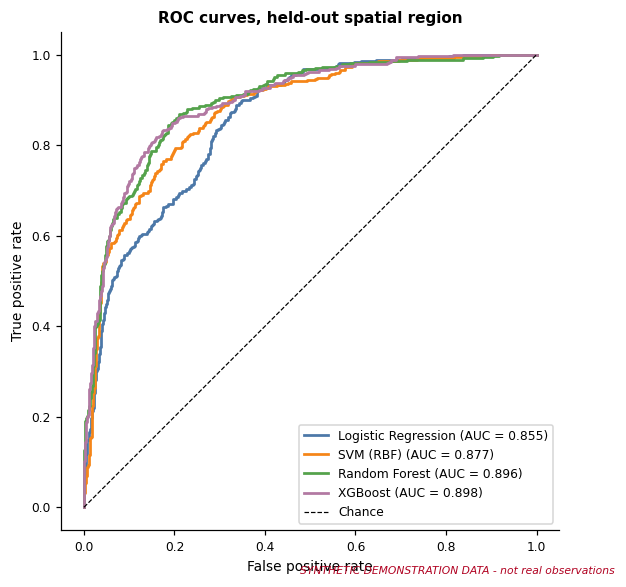

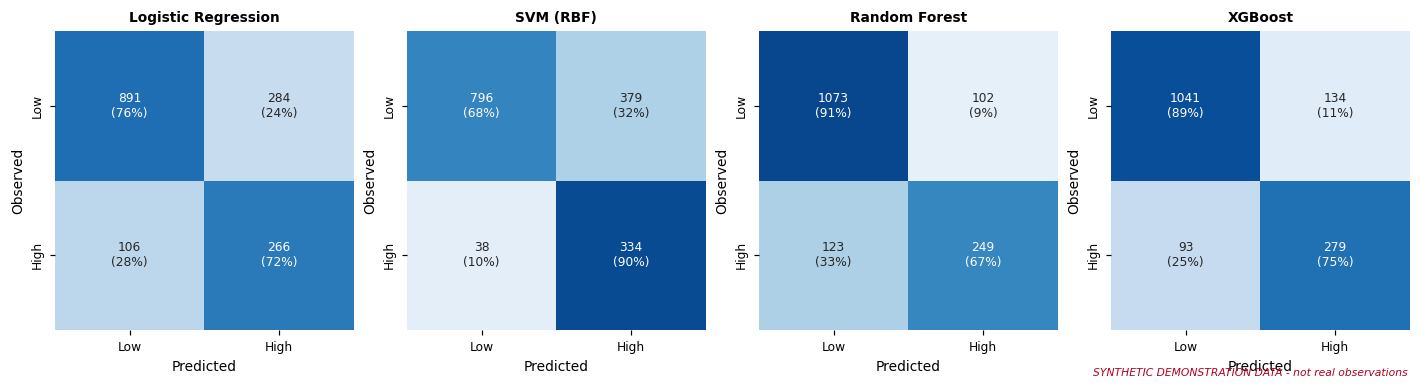

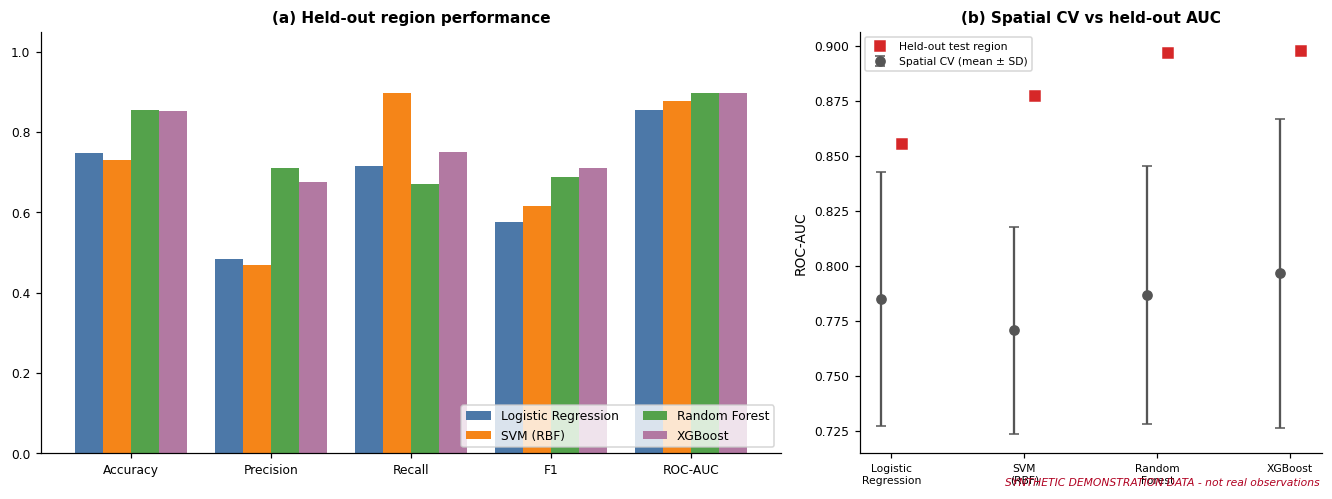

**Interpretation.** Highest held-out ROC-AUC: **XGBoost** (0.898; 95% block-bootstrap CI 0.848–0.933), followed by Random Forest (0.896). The runner-up's AUC lies inside the leader's interval, so the ranking is not clearly resolved with one test region. Spatial-CV AUC on the training region (mean ± SD): Logistic Regression 0.785±0.058; SVM (RBF) 0.771±0.047; Random Forest 0.787±0.059; XGBoost 0.797±0.070.

In [11]:
from sklearn.metrics import roc_auc_score
tab = md.results_table(results); display(tab)

def block_bootstrap_auc(blocks, y, score, n_boot=400, seed=SEED):
    rng = np.random.default_rng(seed); ub = np.unique(blocks); idx = {b: np.where(blocks == b)[0] for b in ub}; out = []
    for _ in range(n_boot):
        pick = np.concatenate([idx[b] for b in rng.choice(ub, size=len(ub), replace=True)])
        if 0 < y[pick].mean() < 1: out.append(roc_auc_score(y[pick], score[pick]))
    return np.percentile(out, [2.5, 97.5])

ci = {n: block_bootstrap_auc(df_te["block"].to_numpy(), y_te, r["score"]) for n, r in results.items()}
tab_ci = tab[["roc_auc"]].assign(ci_low=[ci[n][0] for n in tab.index], ci_high=[ci[n][1] for n in tab.index]); display(tab_ci.round(3))

fig = viz.fig_roc(results); plt.show()
fig = viz.fig_confusion(results); plt.show()
fig = viz.fig_model_comparison(tab, interactive_path="outputs/model_comparison_interactive.html"); plt.show()
tab.to_csv("outputs/model_metrics.csv")

order = tab["roc_auc"].sort_values(ascending=False); best_name, second = order.index[0], order.index[1]
resolved = tab.loc[best_name, "roc_auc"] > ci[second][1] or tab.loc[second, "roc_auc"] < ci[best_name][0]
display(Markdown(f"**Interpretation.** Highest held-out ROC-AUC: **{best_name}** ({order.iloc[0]:.3f}; 95% block-bootstrap CI {ci[best_name][0]:.3f}–{ci[best_name][1]:.3f}), "
                 f"followed by {second} ({order.iloc[1]:.3f}). The runner-up's AUC {'lies outside' if resolved else 'lies inside'} the leader's interval, so the ranking is "
                 f"{'reasonably resolved' if resolved else 'not clearly resolved'} with one test region. Spatial-CV AUC on the training region (mean ± SD): "
                 + "; ".join(f"{n} {r['cv_auc_mean']:.3f}±{r['cv_auc_std']:.3f}" for n, r in results.items()) + "."))

## 12 · Explainable AI

For tree ensembles, **TreeSHAP** computes exact Shapley values $\phi_{i,j}$ such that the model output decomposes additively,

$$ f(x_i) = \phi_0 + \sum_{j=1}^{M}\phi_{i,j}, $$

where $\phi_0$ is the expected model output. We explain the better of Random Forest and XGBoost on the **held-out region** and check the ranking against model-agnostic **permutation importance** (drop in ROC-AUC when a feature is shuffled on unseen data).

*Cautions:* SHAP explains the fitted model, not the physical process; correlated predictors share credit; and the explanation holds only inside the training environmental range.

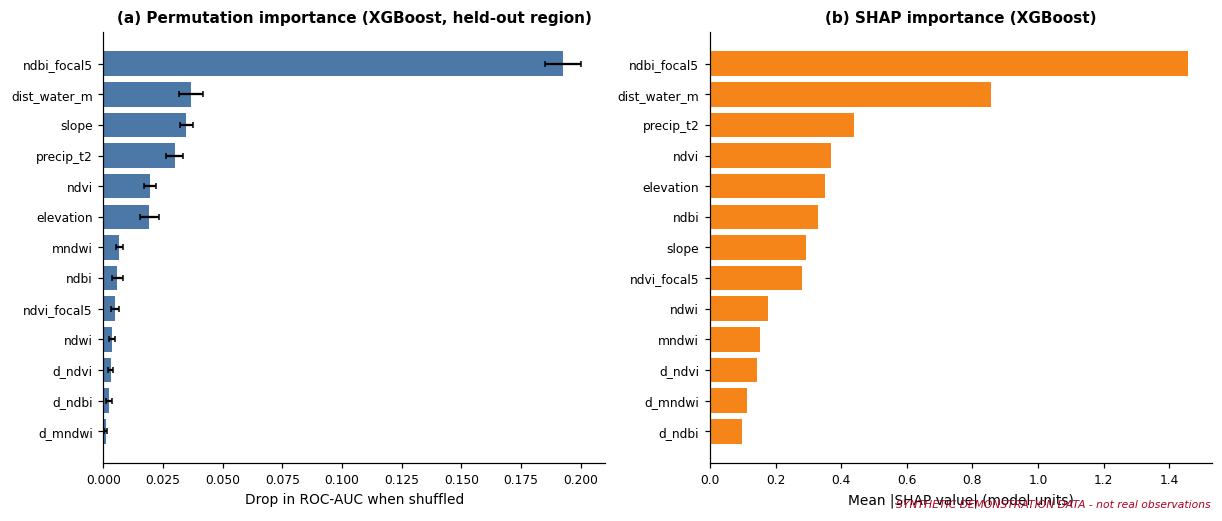

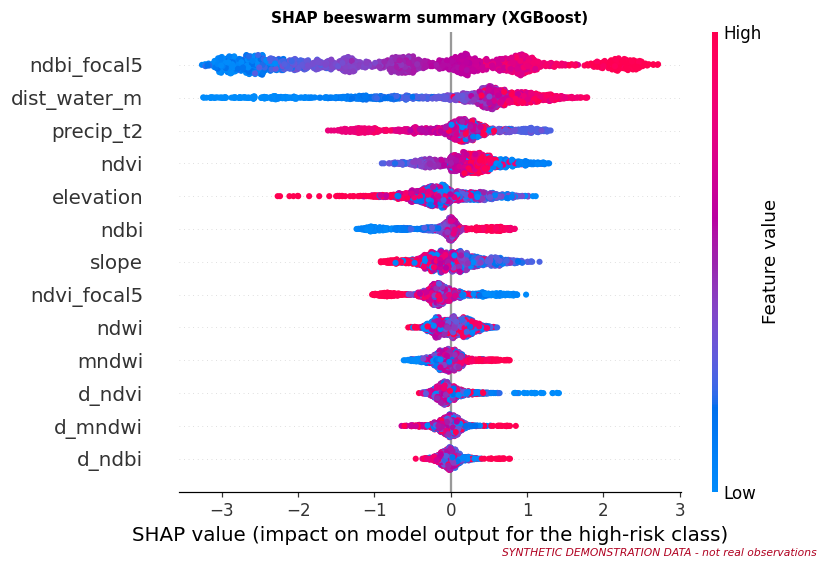

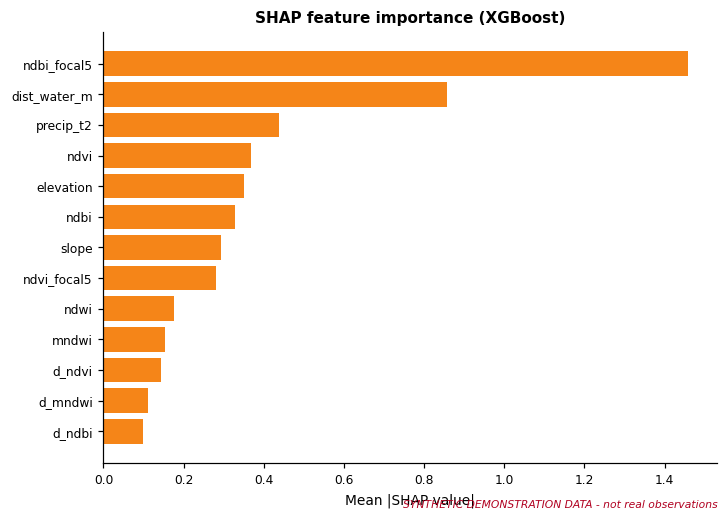

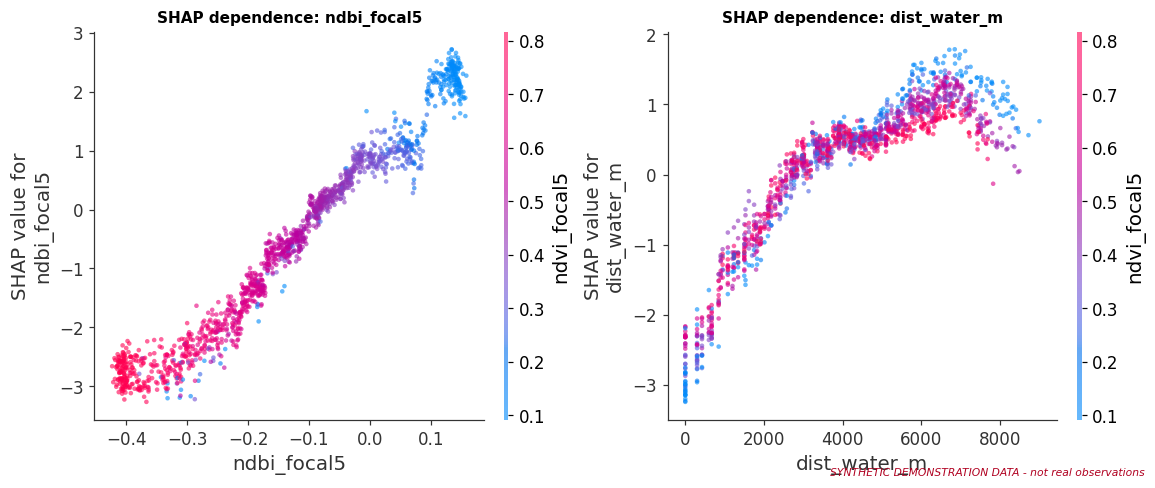

,mean|SHAP|,rank_perm,"rho(value,SHAP)",reading
feature,,,,
ndbi_focal5,1.4574,1,0.9847,higher values raise predicted risk
dist_water_m,0.8580,2,0.9089,higher values raise predicted risk
precip_t2,0.4385,4,-0.5209,higher values lower predicted risk
ndvi,0.3679,5,0.1159,non-monotonic / weak monotonic effect
elevation,0.3507,6,-0.4177,higher values lower predicted risk
ndbi,0.3282,8,0.8740,higher values raise predicted risk


**Interpretation (XGBoost).** The three features with the largest mean |SHAP| are **ndbi_focal5, dist_water_m, precip_t2**; 2 of them also rank in the top three by permutation importance. Direction: `ndbi_focal5` — higher values raise predicted risk (Spearman ρ=+0.98); `dist_water_m` — higher values raise predicted risk (Spearman ρ=+0.91); `precip_t2` — higher values lower predicted risk (Spearman ρ=-0.52). **Spatial-proxy warning:** `precip_t2` is a coarse (~5.5 km) CHIRPS-like field; ranking it among the top predictors suggests the model may use it as a *location identifier* (its blocks are spatially structured) rather than as a physical driver — in this synthetic scene rainfall has no causal link to LST by construction, so this is a direct demonstration of that risk. Because this scene is synthetic, these rankings reveal which simulated drivers the model recovered, not real environmental controls.

In [12]:
from scipy.stats import spearmanr
tree_names = [n for n in ("Random Forest", "XGBoost")]
tree_best = max(tree_names, key=lambda n: results[n]["roc_auc"])
sv, Xt, base = xai.compute_shap_values(fitted[tree_best], X_te, max_samples=1500, seed=SEED)
imp = xai.shap_importance(sv, Xt.columns)
perm = xai.permutation_importance_table(fitted[tree_best], X_te, y_te, n_repeats=10, seed=SEED)
perm.to_csv("outputs/permutation_importance.csv", index=False)

fig = viz.fig_feature_importance(perm, imp, tree_best); plt.show()
fig = viz.fig_shap_beeswarm(sv, Xt, tree_best); plt.show()
fig = viz.fig_shap_bar(imp, tree_best); plt.show()
top2 = list(imp.index[:2]); fig = viz.fig_shap_dependence(sv, Xt, top2, tree_best); plt.show()

def direction(f):
    rho = spearmanr(Xt[f], sv[:, list(Xt.columns).index(f)]).correlation
    return rho, ("higher values raise predicted risk" if rho > 0.25 else "higher values lower predicted risk" if rho < -0.25 else "non-monotonic / weak monotonic effect")

rows = [{"feature": f, "mean|SHAP|": imp[f], "rank_perm": int(perm.index[perm.feature == f][0]) + 1, "rho(value,SHAP)": direction(f)[0], "reading": direction(f)[1]} for f in imp.index[:6]]
shap_tab = pd.DataFrame(rows).set_index("feature"); display(shap_tab)
agree = len(set(imp.index[:3]) & set(perm.feature[:3]))
display(Markdown(f"**Interpretation ({tree_best}).** The three features with the largest mean |SHAP| are **{', '.join(imp.index[:3])}**; {agree} of them also rank in the top three by permutation importance. "
                 + "Direction: " + "; ".join(f"`{f}` — {direction(f)[1]} (Spearman ρ={direction(f)[0]:+.2f})" for f in imp.index[:3]) + ". "
                 + ("**Spatial-proxy warning:** `precip_t2` is a coarse (~5.5 km) CHIRPS-like field; ranking it among the top predictors suggests the model may use it as a *location identifier* (its blocks are spatially structured) rather than as a physical driver"
                    + (" — in this synthetic scene rainfall has no causal link to LST by construction, so this is a direct demonstration of that risk. " if IS_SYNTH else ". Test by dropping it and comparing held-out AUC. ") if "precip_t2" in list(imp.index[:3]) else "")
                 + ("Because this scene is synthetic, these rankings reveal which simulated drivers the model recovered, not real environmental controls." if IS_SYNTH else
                    "These are model-behaviour statements; mechanistic claims about urban heat need independent evidence.")))

## 13 · Geospatial Risk Prediction

The selected tree model (trained on the **training region only**) predicts the probability of the high-LST class for every valid pixel. Only the **held-out region** (black outline) is genuinely out-of-sample; elsewhere the map mixes training and buffer areas and should not be read as validated.

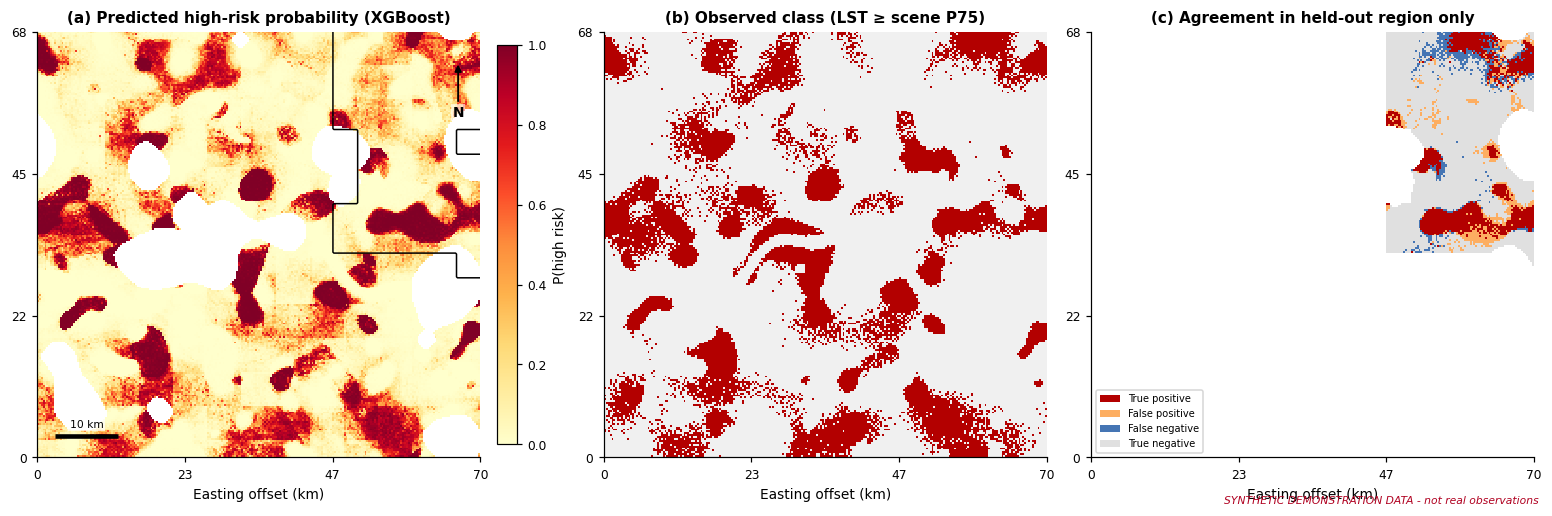

,%
"predicted high-risk share, whole scene (P≥0.5)",24.3400
"observed high-risk share, whole scene",25.0000
"predicted high-risk share, held-out region",25.6800
"observed high-risk share, held-out region",24.1400


**Interpretation.** Compare the predicted and observed high-risk shares in the held-out region: a persistent difference indicates systematic over- or under-prediction at the default 0.5 rule, which an operational use would need to calibrate. Panel (c) shows where errors fall; clustered errors point to spatially structured variation the predictors do not capture.

In [13]:
H, W = y_ras.shape
stack = np.stack([feat_rasters[f] for f in pp.FEATURES], axis=-1).reshape(-1, len(pp.FEATURES))
okpix = np.isfinite(stack).mean(axis=1) >= cfg["sampling"]["min_valid_fraction"]
prob = np.full(H * W, np.nan, dtype="float32")
prob[okpix] = md.positive_scores(fitted[tree_best], pd.DataFrame(stack[okpix], columns=pp.FEATURES))
prob = prob.reshape(H, W)

# Boolean raster of the held-out region, from block (row, col) membership
step = int(round(cfg["cv"]["block_size_m"] / meta["pixel_m"]))
tb = df_te[["brow", "bcol"]].drop_duplicates().to_numpy()
grid = np.zeros((H // step + 2, W // step + 2), dtype=bool); grid[tb[:, 0], tb[:, 1]] = True
rr, cc = np.mgrid[0:H, 0:W]; test_mask = grid[rr // step, cc // step]

fig = viz.fig_risk_map(prob, y_ras, test_mask, meta, 0.5, tree_best); plt.show()

# Export probability raster (GeoTIFF) for GIS use
import rasterio
with rasterio.open("outputs/risk_probability.tif", "w", driver="GTiff", height=H, width=W, count=1, dtype="float32",
                   crs=meta["crs"], transform=meta["transform"], nodata=-9999) as dst:
    dst.write(np.where(np.isfinite(prob), prob, -9999).astype("float32"), 1)

ok_te = test_mask & np.isfinite(prob) & np.isfinite(y_ras)
cover = pd.Series({"predicted high-risk share, whole scene (P≥0.5)": 100 * np.nanmean(prob[np.isfinite(prob)] >= 0.5),
                   "observed high-risk share, whole scene": 100 * np.nanmean(y_ras[np.isfinite(y_ras)]),
                   "predicted high-risk share, held-out region": 100 * np.mean(prob[ok_te] >= 0.5),
                   "observed high-risk share, held-out region": 100 * np.mean(y_ras[ok_te])}, name="%").to_frame()
display(cover.round(2))
import joblib; joblib.dump(fitted[tree_best], f"models/{tree_best.lower().replace(' ', '_')}_pipeline.joblib")
display(Markdown("**Interpretation.** Compare the predicted and observed high-risk shares in the held-out region: a persistent difference indicates systematic over- or under-prediction at the default 0.5 rule, which an operational use would need to calibrate. "
                 "Panel (c) shows where errors fall; clustered errors point to spatially structured variation the predictors do not capture."))

## 14 · RAG Pipeline Development

**Architecture:** documents (PDF/TXT) → text extraction (`pypdf`) → sentence-aware chunks (~110 words, 25-word overlap) → embeddings → **FAISS** inner-product index over unit vectors (cosine) → top-k retrieval → evidence-sufficiency test → source-attributed answer.

**Embeddings.** The configured model is a Sentence-Transformers model. If it cannot be loaded (offline environment, missing package) the pipeline falls back to **TF-IDF + LSA** and *states which backend is active* — retrieval quality numbers below belong to that backend only.

**Answers.** Without an LLM API key, the system returns **extractive evidence** (sentences copied from retrieved chunks, each tagged with its source). It never fabricates an LLM-style answer. If `ANTHROPIC_API_KEY` is set in the environment, the optional generator receives only the retrieved context and is instructed to cite sources or say the evidence is insufficient (that code path is not exercised in this run).

**Sufficiency rule.** An answer is returned only if the best cosine similarity ≥ threshold **and** at least 34 % of the question's keywords appear in retrieved text; otherwise the response is *"Insufficient evidence"*.

The corpus contains the hand-written documentation in `documents/` **plus an auto-generated report of this run's results** (`outputs/model_report.txt`), so questions about model performance are answered from actual outputs.

In [14]:
spatial_auc = cmp.loc["Buffered spatial-block K-fold", "auc_mean"]; random_auc = cmp.loc["Random stratified K-fold", "auc_mean"]
lines = ["GeoRAG-ML automatically generated run report.",
         ("Data mode: SYNTHETIC demonstration scene. The figures below describe a simulated scene and are not findings about any real place."
          if IS_SYNTH else "Data mode: real satellite data loaded from GeoTIFF exports."),
         f"The study uses {info['n_sampled']} sampled pixels, a high-risk threshold of {info['lst_threshold_c']:.2f} degrees Celsius, and a held-out contiguous test region with {integrity['n_test']} samples."]
for n, r in results.items():
    lines.append(f"Held-out region performance of {n}: ROC-AUC {r['roc_auc']:.3f}, F1-score {r['f1']:.3f}, precision {r['precision']:.3f}, recall {r['recall']:.3f}, accuracy {r['accuracy']:.3f}.")
lines += [f"The model with the highest ROC-AUC on the held-out region was {best_name} with {order.iloc[0]:.3f}.",
          f"Validation strategy comparison: random stratified cross-validation gave a mean ROC-AUC of {random_auc:.3f} for the Random Forest, while buffered spatial cross-validation gave {spatial_auc:.3f}, so random splitting overstated performance by {random_auc - spatial_auc:.3f} AUC.",
          f"Most influential predictors: according to mean absolute SHAP values, the most influential predictors of the {tree_best} model were {', '.join(imp.index[:3])}."]
Path("outputs/model_report.txt").write_text("\n".join(lines), encoding="utf-8")

rag = rp.build_rag(cfg, ".", prefer_backend="auto", seed=SEED)
rp.export_chunks(rag.chunks, "outputs/rag_chunks.json")
src_tab = pd.Series([c.source for c in rag.chunks]).value_counts().rename("chunks").to_frame()
display(Markdown(f"**Embedding backend:** {rag.backend_name} · **chunks:** {len(rag.chunks)} · **index:** FAISS `{type(rag.index).__name__}` (dim {rag.embeddings.shape[1]}) · **similarity threshold:** {rag.min_score:.2f}"))
display(src_tab)
for hit in rag.retrieve("What does MNDWI measure and how does it differ from NDWI?", 3):
    print(f"[{hit.rank}] score={hit.score:.3f} {hit.chunk.chunk_id}: {hit.chunk.text[:150]}…")

**Embedding backend:** TF-IDF + LSA fallback (sentence-transformers unavailable) · **chunks:** 39 · **index:** FAISS `IndexFlatIP` (dim 38) · **similarity threshold:** 0.20

,chunks
09_project_data_card.txt,5
01_spectral_indices.txt,4
02_sentinel2_surface_reflectance.txt,4
03_landsat_surface_temperature.txt,4
04_terrain_precipitation_landcover.txt,4
05_machine_learning_methods.txt,4
06_spatial_validation.txt,4
07_shap_explainability.txt,4
08_rag_methodology.txt,4
model_report.txt,2


[1] score=0.507 01_spectral_indices.txt#2: Open water reflects more green than near-infrared light, so water tends to be positive. Built-up surfaces can also produce positive NDWI, which causes…
[2] score=0.408 09_project_data_card.txt#3: Sentinel-2 indices for t2 (NDVI, NDWI, MNDWI, NDBI), 5 by 5 neighbourhood means of NDVI and NDBI, index changes between t2 and t1, distance to open wa…
[3] score=0.380 06_spatial_validation.txt#2: GeoRAG-ML drops training samples in blocks adjacent to the test region. This reduces leakage across block borders but does not eliminate it, and it re…


## 15 · Evidence-Based Question Answering

We test the pipeline in three ways: (1) example answers with their evidence, (2) a **hand-written evaluation set** — in-scope questions with a known source document, plus out-of-scope questions that must be refused — and (3) a similarity heatmap.

> The evaluation set is small and was written by the same author as the documents, so scores are an **upper-bound sanity check of the plumbing**, not a benchmark of retrieval quality on unseen questions.

In [15]:
demo_q = ["How is NDVI calculated?", "Why is MNDWI preferred over NDWI in built-up areas?",
          "Which Sentinel-2 SCL classes are masked?", "Which model had the highest ROC-AUC on the held-out region?",
          "How much did random cross-validation overstate performance?", "What is the capital of France?"]
for q in demo_q:
    a = rag.answer(q, k=cfg["rag"]["top_k"], llm_model=cfg["rag"]["llm_model"])
    print("Q:", q); print("status:", a["status"], "| backend:", a["backend"], "| best score: %.2f | keyword overlap: %.2f" % (a["assessment"]["best_score"], a["assessment"]["overlap"]))
    print(a["answer"][:520]); print("sources:", a["sources"] or "—"); print("-" * 100)

Q: How is NDVI calculated?
status: answered_extractive | backend: TF-IDF + LSA fallback (sentence-transformers unavailable) | best score: 0.59 | keyword overlap: 1.00
Evidence-based extract (no LLM used): Healthy green vegetation reflects strongly in the near-infrared and absorbs red light, which produces high NDVI. [01_spectral_indices.txt] The Normalized Difference Vegetation Index (NDVI) is computed as (NIR - Red) / (NIR + Red), following Rouse and colleagues (1974). [01_spectral_indices.txt] Sentinel-2 indices for t2 (NDVI, NDWI, MNDWI, NDBI), 5 by 5 neighbourhood means of NDVI and NDBI, index changes between t2 and t1, distance to open water, SRTM elevation and slope, and C
sources: ['01_spectral_indices.txt', '09_project_data_card.txt']
----------------------------------------------------------------------------------------------------
Q: Why is MNDWI preferred over NDWI in built-up areas?
status: answered_extractive | backend: TF-IDF + LSA fallback (sentence-transformers unavail

,value
n_in_scope,16.0000
hit_at_4,1.0000
mrr,0.9375
in_scope_answered_rate,0.9375
n_out_of_scope,5.0000
out_of_scope_refusal_rate,1.0000


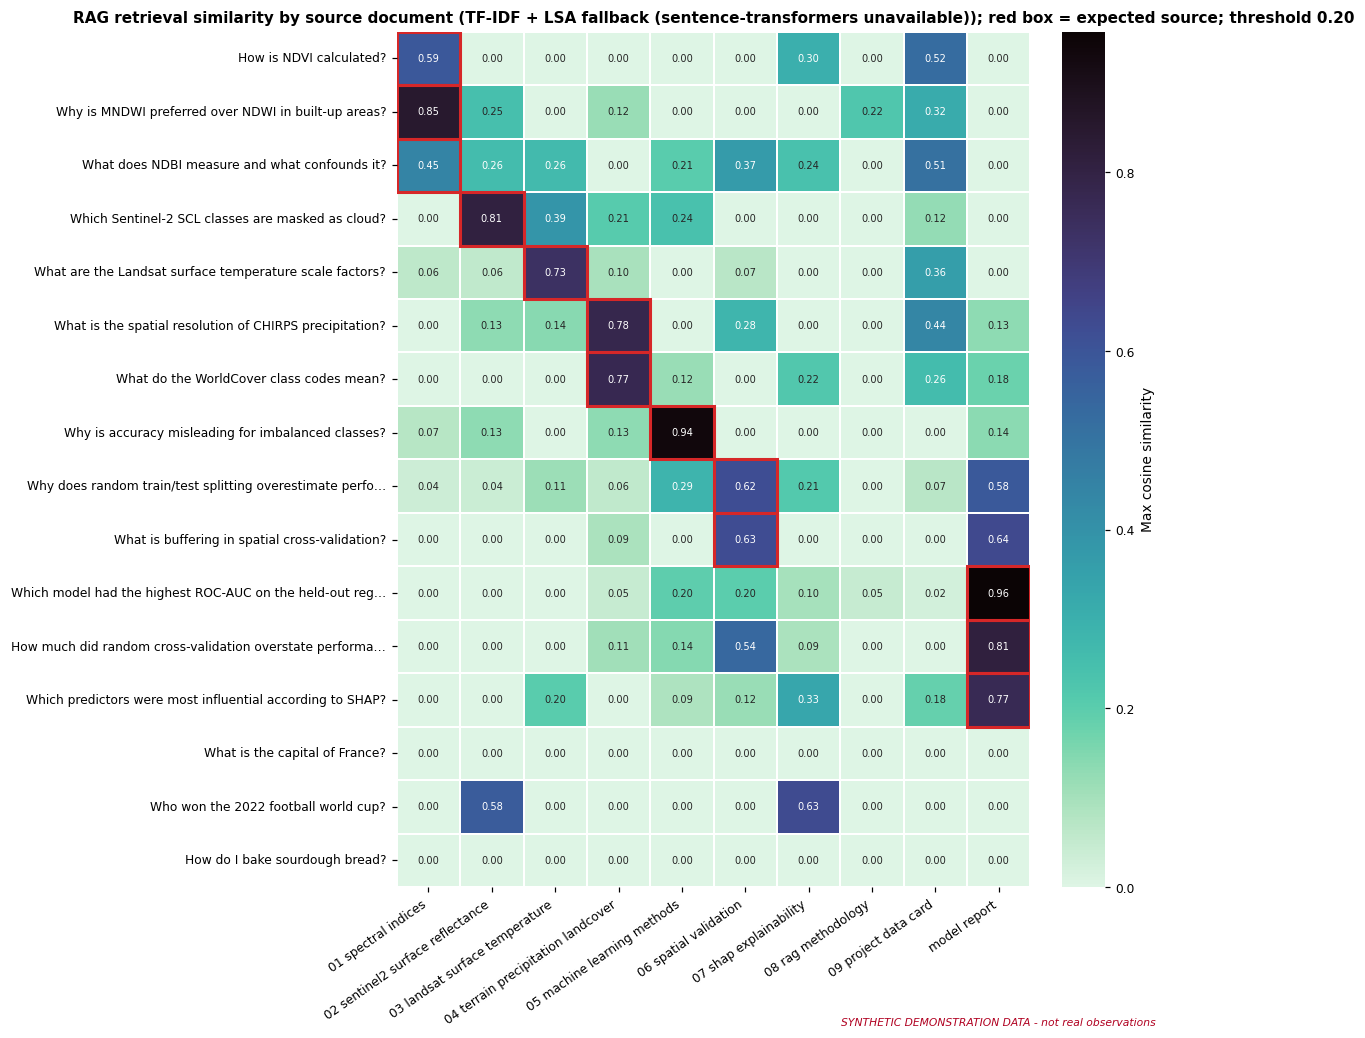

**Interpretation.** On this small set the expected source appears in the top 4 for 100% of in-scope questions (MRR 0.94), and 100% of out-of-scope questions were refused, using the **TF-IDF + LSA fallback (sentence-transformers unavailable)** backend. Note that the model-report questions are answered from this run's own auto-generated report, which makes them verifiable against §11–12.

In [16]:
IN_SCOPE = [
 {"q": "How is NDVI calculated?", "source": "01_spectral_indices.txt"},
 {"q": "Why is MNDWI preferred over NDWI in built-up areas?", "source": "01_spectral_indices.txt"},
 {"q": "What does NDBI measure and what confounds it?", "source": "01_spectral_indices.txt"},
 {"q": "Which Sentinel-2 SCL classes are masked as cloud?", "source": "02_sentinel2_surface_reflectance.txt"},
 {"q": "What are the Landsat surface temperature scale factors?", "source": "03_landsat_surface_temperature.txt"},
 {"q": "What is the spatial resolution of CHIRPS precipitation?", "source": "04_terrain_precipitation_landcover.txt"},
 {"q": "What do the WorldCover class codes mean?", "source": "04_terrain_precipitation_landcover.txt"},
 {"q": "Why is accuracy misleading for imbalanced classes?", "source": "05_machine_learning_methods.txt"},
 {"q": "Why does random train/test splitting overestimate performance on spatial data?", "source": "06_spatial_validation.txt"},
 {"q": "What is buffering in spatial cross-validation?", "source": "06_spatial_validation.txt"},
 {"q": "How do I interpret a SHAP beeswarm plot?", "source": "07_shap_explainability.txt"},
 {"q": "What embedding model and vector index does the RAG system use?", "source": "08_rag_methodology.txt"},
 {"q": "How is the urban heat risk target defined?", "source": "09_project_data_card.txt"},
 {"q": "Which model had the highest ROC-AUC on the held-out region?", "source": "model_report.txt"},
 {"q": "How much did random cross-validation overstate performance?", "source": "model_report.txt"},
 {"q": "Which predictors were most influential according to SHAP?", "source": "model_report.txt"}]
OUT_OF_SCOPE = ["What is the capital of France?", "Who won the 2022 football world cup?", "How do I bake sourdough bread?",
                "What is the population of Dhaka?", "Explain attention heads in large language models."]

ev = rp.evaluate_retrieval(rag, IN_SCOPE, OUT_OF_SCOPE, k=cfg["rag"]["top_k"]); display(pd.Series(ev, name="value").to_frame())
fig, sim_df = viz.fig_rag_similarity(rag, IN_SCOPE[:10] + IN_SCOPE[13:] + [{"q": q} for q in OUT_OF_SCOPE[:3]],
                                     interactive_path="outputs/rag_similarity_interactive.html"); plt.show()
display(Markdown(f"**Interpretation.** On this small set the expected source appears in the top {cfg['rag']['top_k']} for {100*ev['hit_at_4']:.0f}% of in-scope questions (MRR {ev['mrr']:.2f}), "
                 f"and {100*ev['out_of_scope_refusal_rate']:.0f}% of out-of-scope questions were refused, using the **{rag.backend_name}** backend. "
                 "Note that the model-report questions are answered from this run's own auto-generated report, which makes them verifiable against §11–12."))

## 16 · Results and Discussion

The summary below is **generated from this run's computed values** (no hand-typed numbers), organised by research question.

In [17]:
sc = "synthetic demonstration scene" if IS_SYNTH else "real data"
lines = []
lines.append(f"**Scope.** All statements refer to the {sc} analysed in this notebook run.")
lines.append(f"**RQ1 – indices and candidate change.** Median NDVI changed from {np.nanmedian(I1['ndvi']):.3f} to {np.nanmedian(I2['ndvi']):.3f} between {L1} and {L2}. "
             f"Rule-based screening flagged {100*(change>0).sum()/valid.sum():.1f}% of valid pixels as candidate change; these are spectral-index changes, not validated land-cover transitions.")
lines.append(f"**RQ2 – classification.** On the held-out region, {best_name} achieved ROC-AUC {order.iloc[0]:.3f} (95% block-bootstrap CI {ci[best_name][0]:.3f}–{ci[best_name][1]:.3f}) "
             f"and F1 {tab.loc[best_name,'f1']:.3f}; the lowest AUC was {order.index[-1]} ({order.iloc[-1]:.3f}). Ranking resolved between the top two: {'yes' if resolved else 'no'}.")
lines.append(f"**RQ3 – validation optimism.** Random K-fold exceeded buffered spatial CV by {gap:.3f} AUC for the Random Forest.")
lines.append(f"**RQ4 – explanation.** Most influential features for {tree_best} (mean |SHAP|): {', '.join(imp.index[:3])}; {agree}/3 overlap with the permutation-importance top three.")
lines.append(f"**RQ5 – RAG.** Expected source in top-{cfg['rag']['top_k']}: {100*ev['hit_at_4']:.0f}% (n={ev['n_in_scope']}); out-of-scope refusals: {100*ev['out_of_scope_refusal_rate']:.0f}% (n={ev['n_out_of_scope']}); backend: {rag.backend_name}.")
display(Markdown("\n\n".join(lines)))

display(Markdown("""**Discussion.** The comparison between spatial and random validation is the most transferable result of the workflow: it quantifies how much a naive split would have flattered the model. """
                 + ("Because the scene is synthetic, the *absolute* metrics and the feature rankings are properties of the simulator (it generates LST from land cover and distance to water, with a spatial component predictors cannot observe), so they should not be quoted as environmental findings. What the run demonstrates is that the pipeline — masking, indices, leakage-controlled features, buffered spatial CV, SHAP and evidence-gated retrieval — executes end to end and that its safeguards behave as designed. "
                    if IS_SYNTH else
                    "Absolute metrics reflect one study area, one season and one target definition; transferability to other districts or years has not been tested. ")
                 + "Differences between closely ranked models should be read against the bootstrap intervals and spatial-CV standard deviations reported in §10–11."))

# Figure inventory: confirm every mandatory figure was produced
expected = ["fig01_study_area_map", "fig02_satellite_bands", "fig03_ndvi_distribution_map", "fig04_ndwi_mndwi_maps", "fig05_multitemporal_change_map",
            "fig06_landcover_distribution", "fig07_correlation_heatmap", "fig08_feature_importance", "fig09_roc_comparison", "fig10_confusion_matrices",
            "fig11_shap_summary_beeswarm", "fig12_shap_dependence", "fig13_model_performance_comparison", "fig14_environmental_risk_prediction_map",
            "fig15_rag_retrieval_similarity"]
inv = pd.DataFrame({"figure": expected, "exists": [Path(f"figures/{n}.png").exists() for n in expected]}).set_index("figure")
display(inv.T); assert inv["exists"].all(), "Missing mandatory figures"

**Scope.** All statements refer to the synthetic demonstration scene analysed in this notebook run.

**RQ1 – indices and candidate change.** Median NDVI changed from 0.540 to 0.465 between 2019 and 2025. Rule-based screening flagged 19.1% of valid pixels as candidate change; these are spectral-index changes, not validated land-cover transitions.

**RQ2 – classification.** On the held-out region, XGBoost achieved ROC-AUC 0.898 (95% block-bootstrap CI 0.848–0.933) and F1 0.711; the lowest AUC was Logistic Regression (0.855). Ranking resolved between the top two: no.

**RQ3 – validation optimism.** Random K-fold exceeded buffered spatial CV by 0.135 AUC for the Random Forest.

**RQ4 – explanation.** Most influential features for XGBoost (mean |SHAP|): ndbi_focal5, dist_water_m, precip_t2; 2/3 overlap with the permutation-importance top three.

**RQ5 – RAG.** Expected source in top-4: 100% (n=16); out-of-scope refusals: 100% (n=5); backend: TF-IDF + LSA fallback (sentence-transformers unavailable).

**Discussion.** The comparison between spatial and random validation is the most transferable result of the workflow: it quantifies how much a naive split would have flattered the model. Because the scene is synthetic, the *absolute* metrics and the feature rankings are properties of the simulator (it generates LST from land cover and distance to water, with a spatial component predictors cannot observe), so they should not be quoted as environmental findings. What the run demonstrates is that the pipeline — masking, indices, leakage-controlled features, buffered spatial CV, SHAP and evidence-gated retrieval — executes end to end and that its safeguards behave as designed. Differences between closely ranked models should be read against the bootstrap intervals and spatial-CV standard deviations reported in §10–11.

figure,fig01_study_area_map,fig02_satellite_bands,fig03_ndvi_distribution_map,fig04_ndwi_mndwi_maps,fig05_multitemporal_change_map,fig06_landcover_distribution,fig07_correlation_heatmap,fig08_feature_importance,fig09_roc_comparison,fig10_confusion_matrices,fig11_shap_summary_beeswarm,fig12_shap_dependence,fig13_model_performance_comparison,fig14_environmental_risk_prediction_map,fig15_rag_retrieval_similarity
exists,True,True,True,True,True,True,True,True,True,True,True,True,True,True,True


## 17 · Research Limitations

1. **Synthetic mode is not evidence.** When `data/raw/` is empty the notebook simulates data; all quantitative outputs then describe the simulator. Real-world claims require running the Earth Engine export and re-executing.
2. **Target is a relative LST class.** "High risk" means "hottest quarter of the scene" in a late-morning Landsat composite; it is not exposure, vulnerability, air temperature or health risk, and it ignores night-time heat.
3. **Index-based change ≠ land-cover change.** Phenology, soil moisture, residual cloud and sensor differences cause index change without land-cover change. Validated transitions need reference samples and an accuracy assessment.
4. **Spatial validation reduces but does not remove leakage.** Buffers drop adjacent blocks, not the full autocorrelation range; a single held-out region gives one performance estimate; transfer to other regions or years is untested.
5. **Resolution mismatch.** Landsat thermal (100 m native), Sentinel-2 (10–20 m), SRTM (~30 m) and CHIRPS (~5.5 km) are aggregated to one grid; CHIRPS contributes block-wise regional context only.
6. **Shared drivers.** LST and the optical indices respond to the same surface properties, so skill partly reflects shared causes rather than predictive independence; collinear predictors share SHAP credit.
7. **Explanations are model-level.** SHAP shows how the fitted model uses inputs, not causal effects.
8. **RAG scope.** Retrieval is limited to the indexed documents, thresholds are calibrated on a small hand-written set, the TF-IDF/LSA fallback is weaker than a dense model, extractive answers can be incomplete, and the optional LLM path is untested without a key.
9. **Hyper-parameter search is deliberately small** (single-core friendly); larger grids or Bayesian search may change rankings.
10. **Untested components.** `src/gee_acquisition.py` was written against the public Earth Engine API but could not be executed in the offline development environment; the GeoTIFF loader was tested by a write/read round trip on the synthetic scene.

## 18 · Conclusion and Future Research Directions

**Conclusion.** GeoRAG-ML provides a transparent template that links Earth-observation indicators, spatially validated machine learning, SHAP explanations and an evidence-gated retrieval system. Its main design commitments are measurable: target/predictor sensor separation, no coordinate features, pipeline-contained preprocessing, buffered spatial CV with a geographic hold-out, uncertainty via block bootstrap, and a RAG layer that cites sources or declines.

**Future directions**
- Run in real-data mode for Natore and other districts; add Landsat/Sentinel-1 night-time or radar predictors and multi-year composites.
- Replace the percentile label with a validated outcome (e.g. in-situ temperature, heat-related health data) and add vulnerability layers.
- Validate land-cover transitions with stratified reference samples and area-adjusted accuracy estimates.
- Spatial-autocorrelation-aware diagnostics (variograms to set block size; residual Moran's I) and transferability tests across districts and years.
- Calibrate probabilities, tune thresholds for decision costs, and quantify uncertainty with conformal prediction.
- Dense retrieval with a cross-encoder re-ranker, ingestion of peer-reviewed PDFs the user is licensed to use, and a larger independent question set; LLM answer generation with citation verification.

In [18]:
manifest = {"data_mode": mode, "synthetic": bool(IS_SYNTH), "seed": SEED, "versions": versions, "rag_backend": rag.backend_name,
            "n_samples": int(info["n_sampled"]), "best_model_heldout": best_name, "tree_model_explained": tree_best,
            "config": cfg}
Path("outputs/run_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("Saved outputs:", sorted(p.name for p in Path("outputs").glob("*") if p.name != ".gitkeep"))

Saved outputs: ['model_comparison_interactive.html', 'model_metrics.csv', 'model_report.txt', 'permutation_importance.csv', 'rag_chunks.json', 'rag_similarity_interactive.html', 'risk_probability.tif', 'run_manifest.json']


## 19 · References

Bibliographic details were compiled from memory of the published records; please verify volume/page details before formal citation.

- Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
- Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *Proceedings of KDD '16*, 785–794.
- Farr, T. G., et al. (2007). The Shuttle Radar Topography Mission. *Reviews of Geophysics*, 45, RG2004.
- Funk, C., et al. (2015). The climate hazards infrared precipitation with stations—a new environmental record for monitoring extremes. *Scientific Data*, 2, 150066.
- Gorelick, N., et al. (2017). Google Earth Engine: Planetary-scale geospatial analysis for everyone. *Remote Sensing of Environment*, 202, 18–27.
- Johnson, J., Douze, M., & Jégou, H. (2019). Billion-scale similarity search with GPUs. *IEEE Transactions on Big Data*, 7(3), 535–547.
- Lewis, P., et al. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems*, 33, 9459–9474.
- Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *Advances in Neural Information Processing Systems*, 30.
- Lundberg, S. M., et al. (2020). From local explanations to global understanding with explainable AI for trees. *Nature Machine Intelligence*, 2, 56–67.
- McFeeters, S. K. (1996). The use of the Normalized Difference Water Index (NDWI) in the delineation of open water features. *International Journal of Remote Sensing*, 17(7), 1425–1432.
- Olofsson, P., et al. (2014). Good practices for estimating area and assessing accuracy of land change. *Remote Sensing of Environment*, 148, 42–57.
- Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Reimers, N., & Gurevych, I. (2019). Sentence-BERT: Sentence embeddings using Siamese BERT-networks. *Proceedings of EMNLP-IJCNLP 2019*, 3982–3992.
- Roberts, D. R., et al. (2017). Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography*, 40(8), 913–929.
- Rouse, J. W., Haas, R. H., Schell, J. A., & Deering, D. W. (1974). Monitoring vegetation systems in the Great Plains with ERTS. *NASA Special Publication SP-351*, 309–317.
- Xu, H. (2006). Modification of normalised difference water index (NDWI) to enhance open water features in remotely sensed imagery. *International Journal of Remote Sensing*, 27(14), 3025–3033.
- Zha, Y., Gao, J., & Ni, S. (2003). Use of normalized difference built-up index in automatically mapping urban areas from TM imagery. *International Journal of Remote Sensing*, 24(3), 583–594.
- Zanaga, D., et al. ESA WorldCover 10 m land-cover maps (2020 v100; 2021 v200). Zenodo datasets, European Space Agency.